In [1]:
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential, vcirc, FDMDynamicalFrictionForce as FDM_DF
from galpy.orbit import Orbit
import numpy as np
import matplotlib.pyplot as plt
from colossus.halo import concentration, profile_nfw
from colossus.cosmology import cosmology
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import AutoMinorLocator
cosmology.setCosmology('planck15')
#%matplotlib widget
M = 24.627e9

RGC = np.array([1.6, 1.05, 0.43, 0.24, 1.43])#*(2/np.sqrt(3))
MGC = np.array([0.37e5, 1.82e5, 3.63e5, 1.32e5, 1.78e5])
rhm = 0.01
m = 3e-22

Mh = M * 0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)
NFW_pot = NFWPotential(amp=M/A*u.Msun, a=rs*u.kpc)

os = [[r*u.kpc, 0*u.km/u.s, vcirc(NFW_pot, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]

ts = np.linspace(0, 10, 501) * u.Gyr
t = np.linspace(0, 10, 501)

colors = ['tab:blue', 'tab:red', 'tab:green', 'tab:purple', 'black']

def run(i):
    orb_cdf = Orbit(os[i])
    orb_fdf = Orbit(os[i])

    cdf = CDFF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
    fdf = FDM_DF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot, m=m*u.eV)

    orb_cdf.integrate(ts, NFW_pot+cdf, method='dop853_c')
    orb_fdf.integrate(ts, NFW_pot+fdf, method='dop853_c')

    return orb_cdf.r(ts), orb_fdf.r(ts)

res = Parallel(n_jobs=-1)(delayed(run)(i) for i in range(len(RGC)))

rcdf = np.array([r[0] for r in res])
rfdf = np.array([r[1] for r in res])

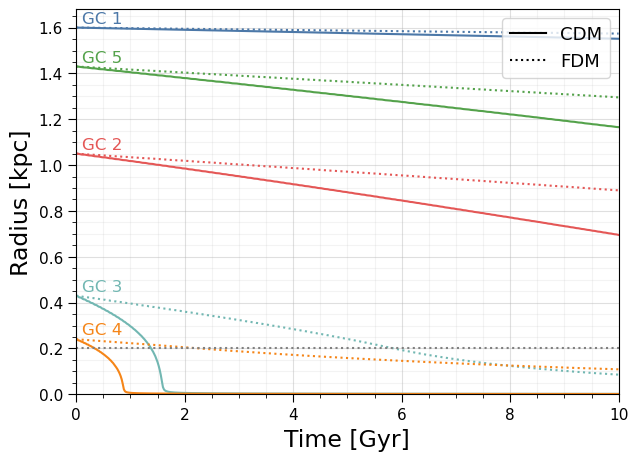

In [5]:
fig, ax = plt.subplots(figsize=(7,5))
colors = ['#4C78A8', '#E45756', '#72B7B2', '#F58518', '#54A24B']
for i in range(len(RGC)):
    col=colors[i]
    ax.plot(t, rcdf[i], color=colors[i],linestyle='-', lw=1.5)
    ax.plot(t, rfdf[i], color=colors[i], linestyle=':', lw=1.5)
    ax.text(t[0] + 0.1, rcdf[i][0]+0.02, f"GC {i+1}", color=col, fontsize=12)
ax.plot([], [], color="black", linestyle="-", label=rf"CDM")
ax.plot([], [], color="black", linestyle=":", label=rf"FDM")
ax.axhline(0.2, color='grey', linestyle=':', linewidth=1.5)

ax.set_xlabel("Time [Gyr]", fontsize=17)
ax.set_ylabel("Radius [kpc]", fontsize=17)

ax.minorticks_on()
"""ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())"""
ax.grid(True, which='major', alpha=0.4)
ax.grid(True, which='minor', alpha=0.15)
ax.tick_params(axis='both', which='major', labelsize=11, length=6)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.68)
ax.legend(frameon=True, fancybox=True, fontsize=13,loc="upper right")
#ax.set_title(r"m = 20 $[10^{{-22}} eV]$")
ax.tick_params(axis='both', labelsize=11)
#plt.tight_layout()
plt.savefig("fdm.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
e=0
M = 24.627e9

RGC = np.array([1.6, 1.05, 0.43, 0.24, 1.43])*(2/np.sqrt(3))
MGC = np.array([0.37e5, 1.82e5, 3.63e5, 1.32e5, 1.78e5])
rhm = 0.01
m = 1e-22

Mh = M * 0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)

NFW_pot = NFWPotential(amp=M/A*u.Msun, a=rs*u.kpc)

os = [[r*u.kpc, 0*u.km/u.s, np.sqrt(1+e)*vcirc(NFW_pot, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]


colors = ['tab:blue', 'tab:red', 'tab:green', 'tab:purple', 'black']

def run(i):
    orb_cdf = Orbit(os[i])
    orb_fdf = Orbit(os[i])

    cdf = CDFF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
    fdf = FDM_DF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot, m=m*u.eV)

    orb_cdf.integrate(ts, NFW_pot+cdf, method='dop853_c')
    orb_fdf.integrate(ts, NFW_pot+fdf, method='dop853_c')

    return orb_cdf.r(ts), orb_fdf.r(ts)

res = Parallel(n_jobs=-1)(delayed(run)(i) for i in range(len(RGC)))

rcdf = np.array([r[0] for r in res])
rfdf = np.array([r[1] for r in res])


fig, ax = plt.subplots()

for i in range(len(RGC)):
    ax.plot(t, rcdf[i], color=colors[i], linestyle='-', lw=1.2, label=f"GC{i+1}")
    ax.plot(t, rfdf[i], color=colors[i], linestyle='--', lw=1.2)

ax.axhline(0.14, color='orange', linestyle=':', linewidth=0.8, label=r"r = 0.14 kpc")

ax.set_xlabel("Time (Gyr)", fontsize=12)
ax.set_ylabel("Radius (kpc)", fontsize=12)

ax.set_xlim(0, 10)
ax.set_ylim(0, 1.75)
ax.legend(frameon=True, fancybox=True, fontsize=10)
ax.set_title(r"m = 20 $[10^{-22} eV]$")
ax.tick_params(axis='both', labelsize=11)
#plt.tight_layout()
plt.savefig("fdm.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#test avec plusieurs m22 pour GC4

R0=0.43
M0=3.63e5
rhm=0.01
v0=vcirc(NFW_pot,R0*u.kpc)*u.km/u.s
o4=[R0*u.kpc,0*u.km/u.s,v0,0*u.kpc,0*u.km/u.s,0*u.deg]
ts=np.linspace(0,14,2000)*u.Gyr
t=ts.value
m22_values=np.logspace(-1,2,10)
results=[]
for m22 in m22_values :
    orb=Orbit(o4)
    fdf=FDM_DF(GMs=M0*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot,m=(m22*1e-22)*u.eV)
    orb.integrate(ts,NFW_pot+fdf,method='dop853_c')
    results.append({"m22":m22,"r":orb.r(ts)})

In [ ]:
cmap=plt.cm.inferno
norm=LogNorm(vmin=m22_values.min(),vmax=m22_values.max())

fig,ax=plt.subplots(figsize=(8,6))
for res in results:
    ax.plot(t,res["r"],color=cmap(norm(res["m22"])),lw=2)
sm=ScalarMappable(cmap=cmap,norm=norm)
sm.set_array([])
cbar=plt.colorbar(sm,ax=ax)
cbar.set_label(r'$m_{22} \; [10^{-22} eV]$',fontsize=16)
ax.set_xlabel(r'$t\ \mathrm{[Gyr]}$',fontsize=18)
ax.set_ylabel(r'$r\ \mathrm{[kpc]}$',fontsize=18)
ax.set_xlim(0,14)
plt.tight_layout()
plt.savefig("m22.png", dpi=300, bbox_inches="tight") 
plt.show()

In [14]:
#boucle m22 pour plusieurs GC
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential, vcirc, FDMDynamicalFrictionForce as FDM_DF
from galpy.orbit import Orbit
import numpy as np
import matplotlib.pyplot as plt
from colossus.halo import concentration, profile_nfw
from colossus.cosmology import cosmology
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from astropy import units as u

from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
from galpy.potential import (TwoPowerSphericalPotential, AnySphericalPotential,evaluateDensities)
from scipy.optimize import minimize, fsolve
from math import pi
import sys
import pandas as pd
import time
from astropy.constants import G
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator
from scipy.signal import argrelextrema
cosmology.setCosmology('planck15')


Ms=2.39e7
rhm=0.01
RGC=np.array([1.6,1.05,0.43,0.24,1.43])*(2/np.sqrt(3))
MGC=np.array([0.37e5,1.82e5,3.63e5,1.32e5,1.78e5])
ts=np.linspace(0,10,1001)*u.Gyr
threshold=0.2
e=0
a=np.sqrt(1+e)
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)
print(M)

rhm = 0.01
RGC=np.array([0.43,0.24])*(2/np.sqrt(3))
MGC=np.array([3.63e5,1.32e5])
e=0

Mh = M * 0.704
c = concentration.concentration(Mh, 'vir', 0, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=Mh, c=c, z=0, mdef='vir')
rs = p_nfw.par['rs']/0.704
A = np.log(1+c)-c/(1+c)
NFW_pot = NFWPotential(amp=M/A*u.Msun, a=rs*u.kpc)
os = [[r*u.kpc, 0*u.km/u.s, np.sqrt(1+e)*vcirc(NFW_pot, r*u.kpc)*u.km/u.s, 0*u.kpc, 0*u.km/u.s, 0*u.deg] for r in RGC]


ts=np.linspace(0,10,1001)*u.Gyr
t=ts.value
m22_values=np.logspace(np.log10(0.5),np.log10(40),10)
all_results=[]

for o,mgc in zip(os,MGC):
    gc_results=[]
    for m22 in m22_values:
        orb=Orbit(o)
        fdf=FDM_DF(GMs=mgc*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot,m=(m22*1e-22)*u.eV)
        orb.integrate(ts,NFW_pot+fdf,method='dop853_c')
        gc_results.append({"m22":m22,"r":orb.r(ts)})
    all_results.append(gc_results)


24627779284.061565


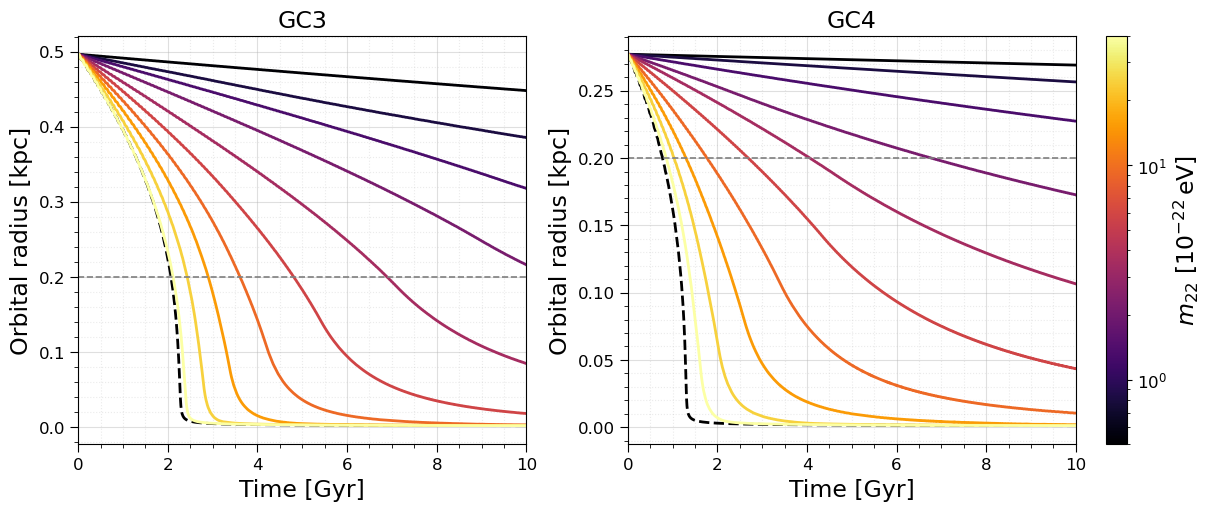

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, constrained_layout=True)

cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())

for i, ax in enumerate(axes):
    orb_classic = Orbit(os[i])
    cdf = CDFF(GMs=MGC[i]*u.Msun, rhm=rhm*u.kpc, dens=NFW_pot)
    orb_classic.integrate(ts, NFW_pot + cdf, method='dop853_c')
    ax.plot(t, orb_classic.r(ts), color='black', lw=2, ls='--', label='CDFF (classique)')
    for res in all_results[i]:
        ax.plot(t, res["r"], color=cmap(norm(res["m22"])), lw=2)
        
        """ax.text(
            t[-1],
            res["r"][-1],
            f'{res["m22"]:.2f}',
            color=cmap(norm(res["m22"])),
            fontsize=8,
            ha='left',
            va='center',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1)
        )"""
        
    ax.axhline(0.2, color='grey', linestyle='--', lw=1.2)#, label="0.2 kpc")
    ax.set_title(f'GC{i+3}', fontsize=17)
    ax.set_xlabel("Time [Gyr]", fontsize=17)
    ax.set_ylabel("Orbital radius [kpc]", fontsize=17)
    #ax.legend(loc="upper right")
    ax.set_xlim(0, 10)
    #ax.set_ylim(0,0.45)
    ax.minorticks_on()

    ax.grid(True, which='major', linestyle='-', alpha=0.4)
    ax.grid(True, which='minor', linestyle=':', alpha=0.25)

    ax.tick_params(axis='both', which='major', labelsize=12, length=6)
    ax.tick_params(axis='both', which='minor', length=3)
    #ax.set_ylim(0.18,0.23)

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes, pad=0.02)
cbar.set_label(r'$m_{22}\ [10^{-22}\,\mathrm{eV}]$', fontsize=17)
cbar.ax.tick_params(labelsize=12)
plt.savefig("m22_2GC2.png", dpi=300, bbox_inches="tight")
plt.show()

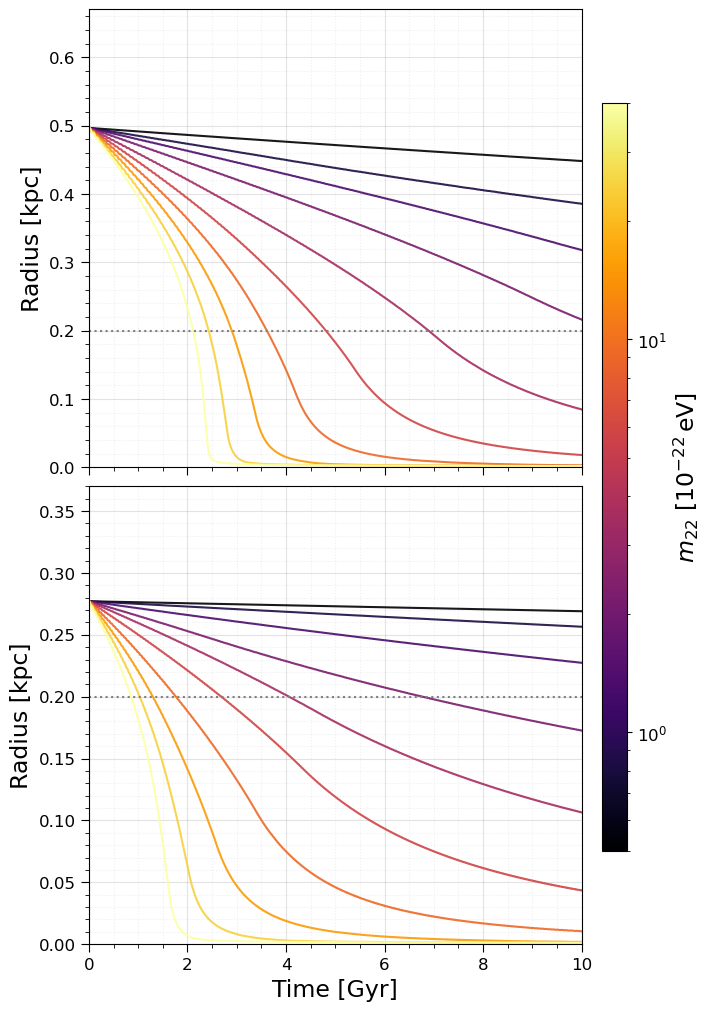

In [18]:

fig, axes = plt.subplots(
    2, 1,                    
    figsize=(7, 10),
    sharex=True,
    constrained_layout=True
)

cmap = plt.cm.inferno
norm = LogNorm(vmin=m22_values.min(), vmax=m22_values.max())
y=[0.67,0.37]         #[0.435,0.242]     
for i, ax in enumerate(axes):
    for res in all_results[i]:
        ax.plot(t, res["r"], color=cmap(norm(res["m22"])),alpha=0.9, lw=1.5)

    ax.axhline(0.2, color='grey', linestyle=':', lw=1.5)

    #ax.set_title(f'GC{i+3}', fontsize=17)

    ax.set_ylabel("Radius [kpc]", fontsize=17)

    ax.set_xlim(0, 10)
    ax.set_ylim(0,y[i])

    # Minor ticks
    ax.minorticks_on()

    # Grid
    ax.grid(True, which='major', linestyle='-', alpha=0.35)
    ax.grid(True, which='minor', linestyle=':', alpha=0.2)

    # Ticks
    ax.tick_params(axis='both', which='major', labelsize=12, length=6)
    ax.tick_params(axis='both', which='minor', length=3)
ax.set_xlabel("Time [Gyr]", fontsize=17)
sm = ScalarMappable(cmap=cmap , norm=norm)
sm.set_array([])

# Colorbar verticale pour les deux plots
cbar = fig.colorbar(sm, ax=axes, pad=0.02,shrink=0.8,aspect=30)
cbar.set_label(r'$m_{22}\ [10^{-22}\,\mathrm{eV}]$', fontsize=17)
cbar.ax.tick_params(labelsize=12)

plt.savefig("m22_2GC2.png", dpi=300, bbox_inches="tight")
plt.show()